<a href="https://colab.research.google.com/github/mazenkoz/artificial-intelligence-coursework/blob/main/Task2_TextMining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: Text Mining and Document Clustering
**CN6005 Artificial Intelligence – Group Coursework**

Dataset: *Real / Fake Job Posting Prediction* (Bansal, Kaggle) – 17,880 job adverts, 866 of them labelled as fraudulent.

Notebook sections:
1. Dataset loading and exploration (2.1)
2. Text pre-processing (2.2)
3. TF-IDF feature extraction (2.3)
4. K-Means clustering with the Elbow Method and Silhouette Score (2.4)
5. Sentence-BERT embeddings and comparison with TF-IDF (2.5)
6. Results summary (2.6)

In [ ]:
# Install the required libraries
%pip -q install kagglehub sentence-transformers nltk

import kagglehub

# Download the Real / Fake Job Posting dataset from Kaggle
dataset_path = kagglehub.dataset_download(
    "shivamb/real-or-fake-fake-jobposting-prediction"
)

print("Dataset downloaded to:")
print(dataset_path)

Using Colab cache for faster access to the 'real-or-fake-fake-jobposting-prediction' dataset.
Dataset downloaded to:
/kaggle/input/real-or-fake-fake-jobposting-prediction


In [ ]:
# Import the libraries
import re
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Download the NLTK resources used for pre-processing
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

# Set random seeds
random.seed(42)
np.random.seed(42)

# Set a consistent graph style
sns.set_style("whitegrid")

# Create a folder for saving results
output_dir = Path("/content/task2_results")
output_dir.mkdir(parents=True, exist_ok=True)

print("Libraries loaded")

Libraries loaded


## 2.1 Dataset Selection and Exploration

In [ ]:
# Find the CSV file inside the downloaded folder
csv_files = list(Path(dataset_path).rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV file was found in the dataset folder.")

df = pd.read_csv(csv_files[0])

print("File loaded:", csv_files[0].name)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(list(df.columns))

df.head()

File loaded: fake_job_postings.csv
Dataset shape: (17880, 18)

Columns:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


Percentage of missing values per column:
salary_range           84.0
department             64.6
required_education     45.3
benefits               40.3
required_experience    39.4
function               36.1
industry               27.4
employment_type        19.4
company_profile        18.5
requirements           15.1
location                1.9
description             0.0
title                   0.0
job_id                  0.0
telecommuting           0.0
has_questions           0.0
has_company_logo        0.0
fraudulent              0.0
dtype: float64


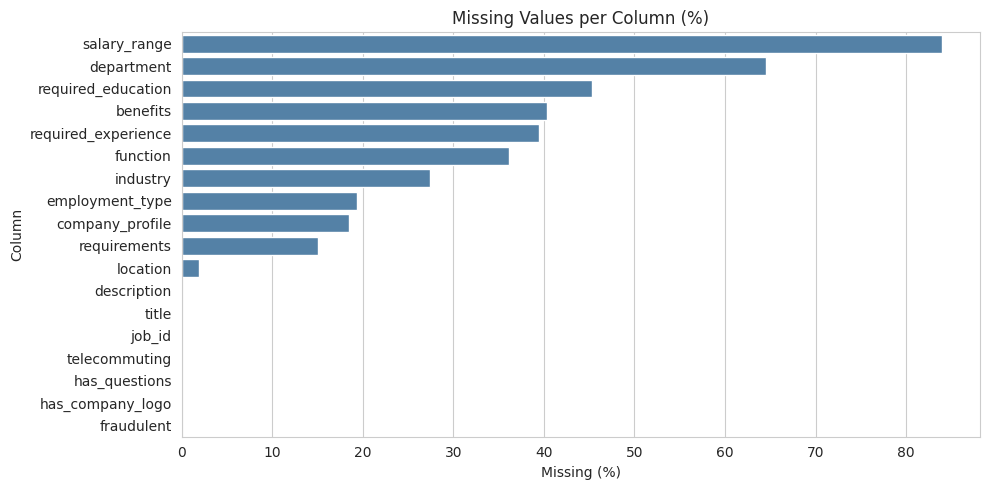

In [ ]:
# Check missing values in each column
missing = (df.isnull().mean() * 100).sort_values(ascending=False)

print("Percentage of missing values per column:")
print(missing.round(1))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing.values,
    y=missing.index,
    color="steelblue"
)

plt.title("Missing Values per Column (%)")
plt.xlabel("Missing (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.savefig(output_dir / "missing_values.png", dpi=150)
plt.show()

Real and fake postings:
fraudulent
Real    17014
Fake      866
Name: count, dtype: int64
Fake postings (%): 4.84


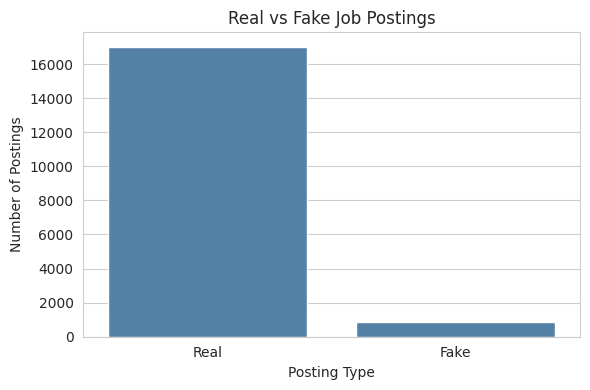

In [ ]:
# Plot the number of real and fake job postings
fraud_counts = df["fraudulent"].value_counts().rename(
    {0: "Real", 1: "Fake"}
)

print("Real and fake postings:")
print(fraud_counts)
print("Fake postings (%):",
      round(fraud_counts["Fake"] / len(df) * 100, 2))

plt.figure(figsize=(6, 4))

sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values,
    color="steelblue"
)

plt.title("Real vs Fake Job Postings")
plt.xlabel("Posting Type")
plt.ylabel("Number of Postings")
plt.tight_layout()
plt.savefig(output_dir / "real_vs_fake.png", dpi=150)
plt.show()

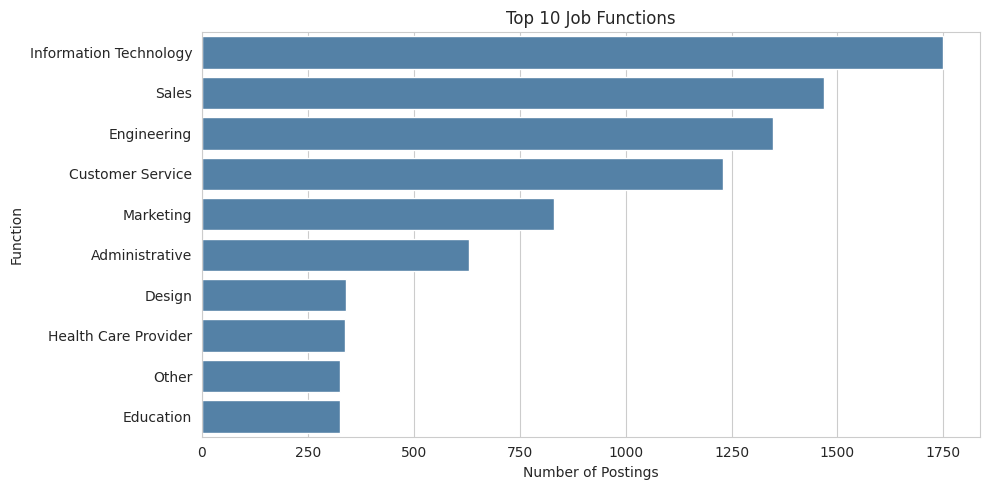

Employment types:
employment_type
Full-time    11620
NaN           3471
Contract      1524
Part-time      797
Temporary      241
Other          227
Name: count, dtype: int64


In [ ]:
# Plot the ten most common job functions
top_functions = df["function"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_functions.values,
    y=top_functions.index,
    color="steelblue"
)

plt.title("Top 10 Job Functions")
plt.xlabel("Number of Postings")
plt.ylabel("Function")
plt.tight_layout()
plt.savefig(output_dir / "top_functions.png", dpi=150)
plt.show()

# Show the most common employment types
print("Employment types:")
print(df["employment_type"].value_counts(dropna=False))

Each job posting is split across several text columns. They are combined into one document per posting so that the
clustering uses the full advert (title, company profile, description, requirements and benefits).

In [ ]:
# Combine the text columns into one document per job posting
text_columns = [
    "title", "company_profile", "description",
    "requirements", "benefits"
]

df["text"] = df[text_columns].fillna("").agg(" ".join, axis=1)

# Remove exact duplicate documents
before = len(df)
df = df.drop_duplicates(subset="text").reset_index(drop=True)

print("Documents before duplicate removal:", before)
print("Duplicate documents removed:", before - len(df))

# Count the words in each document
df["word_count"] = df["text"].str.split().str.len()

# Remove very short documents that contain little information
df = df[df["word_count"] >= 20].reset_index(drop=True)

print("Documents after removing very short adverts:", len(df))
print("\nWord count summary:")
print(df["word_count"].describe().round(1))

Documents before duplicate removal: 17880
Duplicate documents removed: 1814
Documents after removing very short adverts: 16037

Word count summary:
count    16037.0
mean       391.7
std        202.0
min         20.0
25%        248.0
50%        365.0
75%        503.0
max       2118.0
Name: word_count, dtype: float64


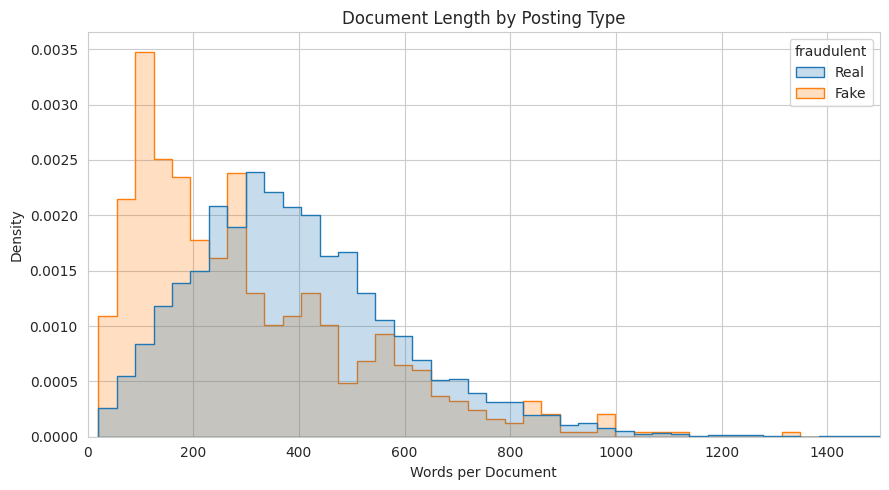

Median words (real): 370.0
Median words (fake): 247.0


In [ ]:
# Plot the document length distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue=df["fraudulent"].map({0: "Real", 1: "Fake"}),
    bins=60,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Document Length by Posting Type")
plt.xlabel("Words per Document")
plt.ylabel("Density")
plt.xlim(0, 1500)
plt.tight_layout()
plt.savefig(output_dir / "word_count_distribution.png", dpi=150)
plt.show()

print("Median words (real):",
      df.loc[df["fraudulent"] == 0, "word_count"].median())
print("Median words (fake):",
      df.loc[df["fraudulent"] == 1, "word_count"].median())

A random sample of 5,000 postings is used for clustering. This keeps the Sentence-BERT encoding and the repeated
K-Means runs manageable on Google Colab while still exceeding the 1,000-document requirement.

In [ ]:
# Use a random sample for faster execution
sample_size = 5000

df = df.sample(
    n=min(sample_size, len(df)),
    random_state=42
).reset_index(drop=True)

assert len(df) >= 1000, "Dataset must contain at least 1,000 documents"

print("Documents used for clustering:", len(df))
print("Fake postings in the sample:", df["fraudulent"].sum())
print("\nDataset meets the coursework size requirement.")

Documents used for clustering: 5000
Fake postings in the sample: 238

Dataset meets the coursework size requirement.


## 2.2 Text Pre-processing

In [ ]:
# Set up the stop-word list and lemmatiser
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


def basic_clean(text):
    """Remove dataset placeholders and fix joined words."""

    # The dataset replaces links, emails and phones with tags like #URL_abc#
    text = re.sub(r"#(URL|EMAIL|PHONE)_[^#]*#", " ", text)

    # Remove any HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Split words that were joined when line breaks were removed
    # e.g. "our teamWe are" -> "our team We are"
    text = re.sub(r"([a-z])([A-Z])", r"\1 \2", text)

    # Remove extra spaces
    return re.sub(r"\s+", " ", text).strip()


def preprocess(text):
    """Full pre-processing pipeline used for TF-IDF."""

    # Clean placeholders and joined words
    text = basic_clean(text)

    # Lowercase the text
    text = text.lower()

    # Remove punctuation, numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Split the text into tokens
    tokens = word_tokenize(text)

    # Remove stop words and very short tokens
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]

    # Reduce each word to its dictionary form
    tokens = [lemmatizer.lemmatize(t) for t in tokens]

    return " ".join(tokens)


# Apply the pre-processing
start_time = time.time()

df["clean_text"] = df["text"].apply(preprocess)

print("Pre-processing time (seconds):",
      round(time.time() - start_time, 2))

Pre-processing time (seconds): 55.46


In [ ]:
# Show each pre-processing step for one example document
example = df["text"].iloc[0][:400]

step1 = basic_clean(example)
step2 = step1.lower()
step3 = re.sub(r"[^a-z\s]", " ", step2)
step4 = word_tokenize(step3)
step5 = [t for t in step4 if t not in stop_words and len(t) > 2]
step6 = [lemmatizer.lemmatize(t) for t in step5]

steps = pd.DataFrame({
    "Step": [
        "Original text",
        "Placeholders removed / joined words split",
        "Lowercasing",
        "Punctuation and special characters removed",
        "Tokenisation",
        "Stop-word removal",
        "Lemmatisation"
    ],
    "Output": [
        example[:200],
        step1[:200],
        step2[:200],
        step3[:200],
        str(step4[:25]),
        str(step5[:25]),
        str(step6[:25])
    ]
})

pd.set_option("display.max_colwidth", 200)
display(steps)

steps.to_csv(output_dir / "preprocessing_example.csv", index=False)

# Show examples of lemmatisation
for word in ["services", "companies", "managing", "skills", "studies"]:
    print(f"{word:>10} -> {lemmatizer.lemmatize(word)}")

,Step,Output
0,Original text,"Service Delivery Manager 1 Novitex Enterprise Solutions, formerly Pitney Bowes Management Services, delivers innovative document and communications management solutions that help companies around..."
1,Placeholders removed / joined words split,"Service Delivery Manager 1 Novitex Enterprise Solutions, formerly Pitney Bowes Management Services, delivers innovative document and communications management solutions that help companies around ..."
2,Lowercasing,"service delivery manager 1 novitex enterprise solutions, formerly pitney bowes management services, delivers innovative document and communications management solutions that help companies around ..."
3,Punctuation and special characters removed,service delivery manager novitex enterprise solutions formerly pitney bowes management services delivers innovative document and communications management solutions that help companies around ...
4,Tokenisation,"['service', 'delivery', 'manager', 'novitex', 'enterprise', 'solutions', 'formerly', 'pitney', 'bowes', 'management', 'services', 'delivers', 'innovative', 'document', 'and', 'communications', 'ma..."
5,Stop-word removal,"['service', 'delivery', 'manager', 'novitex', 'enterprise', 'solutions', 'formerly', 'pitney', 'bowes', 'management', 'services', 'delivers', 'innovative', 'document', 'communications', 'managemen..."
6,Lemmatisation,"['service', 'delivery', 'manager', 'novitex', 'enterprise', 'solution', 'formerly', 'pitney', 'bowes', 'management', 'service', 'delivers', 'innovative', 'document', 'communication', 'management',..."


  services -> service
 companies -> company
  managing -> managing
    skills -> skill
   studies -> study


In [ ]:
# Compare document length before and after pre-processing
df["clean_word_count"] = df["clean_text"].str.split().str.len()

print("Average words before:", round(df["word_count"].mean(), 1))
print("Average words after:", round(df["clean_word_count"].mean(), 1))
print("Reduction (%):",
      round((1 - df["clean_word_count"].mean() / df["word_count"].mean()) * 100, 1))

Average words before: 390.3
Average words after: 257.2
Reduction (%): 34.1


## 2.3 Feature Extraction Using TF-IDF

In [ ]:
# Generate TF-IDF vectors
tfidf = TfidfVectorizer(
    max_features=5000,     # keep the 5,000 most frequent terms
    min_df=5,              # ignore terms in fewer than 5 documents
    max_df=0.8,            # ignore terms in more than 80% of documents
    ngram_range=(1, 2)     # use single words and two-word phrases
)

X_tfidf = tfidf.fit_transform(df["clean_text"])
terms = np.array(tfidf.get_feature_names_out())

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Matrix sparsity (%):",
      round((1 - X_tfidf.nnz / np.prod(X_tfidf.shape)) * 100, 2))

TF-IDF matrix shape: (5000, 5000)
Matrix sparsity (%): 96.22


,Term,Mean TF-IDF
0,team,0.0362
1,work,0.0360
2,customer,0.0337
3,service,0.0322
4,company,0.0289
5,business,0.0287
6,sale,0.0282
7,client,0.0280
8,product,0.0274
9,skill,0.0257


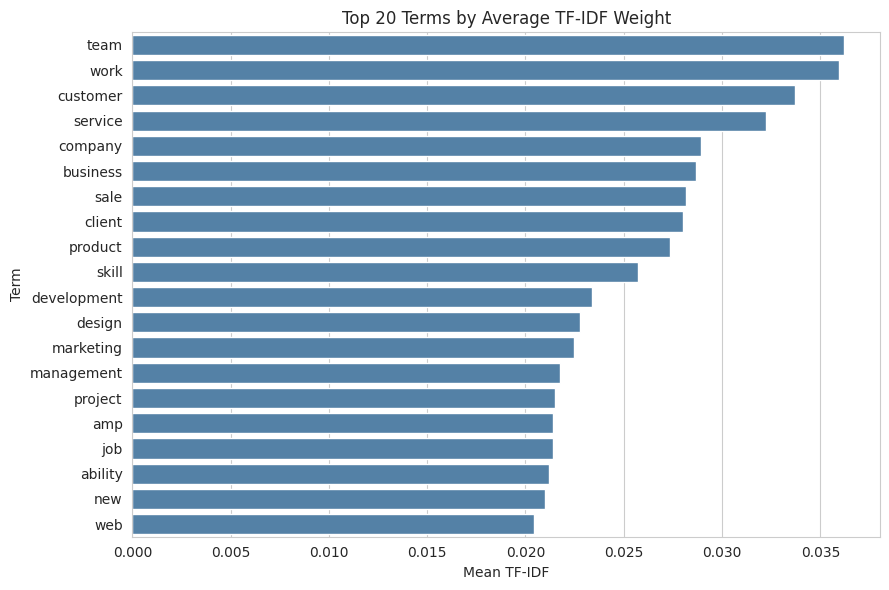

In [ ]:
# Identify the key terms with the highest average TF-IDF weight
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_index = mean_tfidf.argsort()[::-1][:20]

top_terms = pd.DataFrame({
    "Term": terms[top_index],
    "Mean TF-IDF": mean_tfidf[top_index]
})

display(top_terms.round(4))

plt.figure(figsize=(9, 6))

sns.barplot(
    data=top_terms,
    x="Mean TF-IDF",
    y="Term",
    color="steelblue"
)

plt.title("Top 20 Terms by Average TF-IDF Weight")
plt.tight_layout()
plt.savefig(output_dir / "top_tfidf_terms.png", dpi=150)
plt.show()

top_terms.to_csv(output_dir / "top_tfidf_terms.csv", index=False)

In [ ]:
# Compare key terms in real and fake postings
real_mask = (df["fraudulent"] == 0).values
fake_mask = (df["fraudulent"] == 1).values

real_mean = np.asarray(X_tfidf[real_mask].mean(axis=0)).ravel()
fake_mean = np.asarray(X_tfidf[fake_mask].mean(axis=0)).ravel()

difference = fake_mean - real_mean

term_compare = pd.DataFrame({
    "More common in fake postings": terms[difference.argsort()[::-1][:15]],
    "More common in real postings": terms[difference.argsort()[:15]]
})

display(term_compare)
term_compare.to_csv(output_dir / "real_vs_fake_terms.csv", index=False)

,More common in fake postings,More common in real postings
0,data entry,web
1,entry,team
2,aker,marketing
3,aker solution,medium
4,oil,digital
5,earn,client
6,home,user
7,administrative,social
8,position,developer
9,work home,growing


## 2.4 Document Clustering Using K-Means

TF-IDF vectors have thousands of sparse dimensions, which makes distances between documents less meaningful.
Truncated SVD (Latent Semantic Analysis) is used to reduce them to 50 dimensions, matching the 50 PCA components
used later for the Transformer embeddings so both methods are clustered in a space of the same size.

In [ ]:
# Reduce the TF-IDF vectors to 50 dimensions
svd = TruncatedSVD(n_components=50, random_state=42)

X_tfidf_svd = normalize(svd.fit_transform(X_tfidf))

print("Reduced TF-IDF shape:", X_tfidf_svd.shape)
print("Variance explained by 50 components (%):",
      round(svd.explained_variance_ratio_.sum() * 100, 2))

Reduced TF-IDF shape: (5000, 50)
Variance explained by 50 components (%): 24.72


K selection time (seconds): 41.27


,K,Inertia,Silhouette
0,2,3371.2742,0.0632
1,3,3218.0042,0.0552
2,4,3119.8933,0.0626
3,5,2998.5382,0.0754
4,6,2895.5497,0.0911
5,7,2807.0765,0.0945
6,8,2722.8019,0.0954
7,9,2635.0269,0.1106
8,10,2562.8635,0.1244
9,11,2514.4734,0.1258


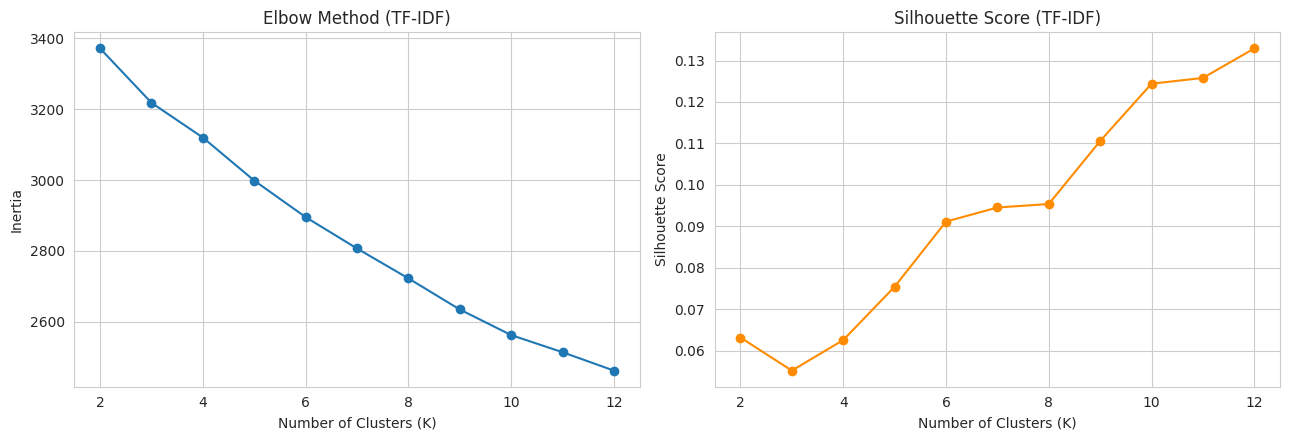

In [ ]:
def evaluate_k_values(X, k_values):
    """Run K-Means for several K values and record inertia and silhouette."""

    rows = []

    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(X)

        rows.append({
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette_score(X, labels)
        })

    return pd.DataFrame(rows)


def plot_k_selection(results, title, filename):
    """Plot the Elbow Method and Silhouette Score side by side."""

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(results["K"], results["Inertia"], marker="o")
    axes[0].set_title(f"Elbow Method ({title})")
    axes[0].set_xlabel("Number of Clusters (K)")
    axes[0].set_ylabel("Inertia")

    axes[1].plot(results["K"], results["Silhouette"],
                 marker="o", color="darkorange")
    axes[1].set_title(f"Silhouette Score ({title})")
    axes[1].set_xlabel("Number of Clusters (K)")
    axes[1].set_ylabel("Silhouette Score")

    plt.tight_layout()
    plt.savefig(output_dir / filename, dpi=150)
    plt.show()


# Test K values from 2 to 12
k_values = range(2, 13)

start_time = time.time()
tfidf_k_results = evaluate_k_values(X_tfidf_svd, k_values)

print("K selection time (seconds):", round(time.time() - start_time, 2))
display(tfidf_k_results.round(4))

plot_k_selection(tfidf_k_results, "TF-IDF", "tfidf_k_selection.png")

In [ ]:
# Choose K using the highest silhouette score.
# K = 2 is excluded because two very broad groups are not useful
# for describing the different types of job advert.
candidates = tfidf_k_results[tfidf_k_results["K"] >= 3]
best_k_tfidf = int(candidates.loc[candidates["Silhouette"].idxmax(), "K"])

print("Selected K for TF-IDF:", best_k_tfidf)

Selected K for TF-IDF: 12


In [ ]:
# Apply K-Means with the selected K
kmeans_tfidf = KMeans(
    n_clusters=best_k_tfidf,
    random_state=42,
    n_init=20
)

df["tfidf_cluster"] = kmeans_tfidf.fit_predict(X_tfidf_svd)

cluster_counts = df["tfidf_cluster"].value_counts().sort_index()

print("Documents per TF-IDF cluster:")
print(cluster_counts)

Documents per TF-IDF cluster:
tfidf_cluster
0     417
1     511
2     135
3     455
4     654
5     105
6     850
7     651
8     613
9      68
10    359
11    182
Name: count, dtype: int64


In [ ]:
def top_terms_per_cluster(cluster_labels, n_terms=10):
    """Return the highest average TF-IDF terms for each cluster."""

    rows = []

    for cluster in sorted(np.unique(cluster_labels)):
        mask = cluster_labels == cluster
        centre = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
        best = centre.argsort()[::-1][:n_terms]

        rows.append({
            "Cluster": cluster,
            "Documents": int(mask.sum()),
            "Fake (%)": round(df.loc[mask, "fraudulent"].mean() * 100, 2),
            "Top Terms": ", ".join(terms[best])
        })

    return pd.DataFrame(rows)


# Interpret each TF-IDF cluster using its key terms
tfidf_cluster_terms = top_terms_per_cluster(df["tfidf_cluster"].values)

display(tfidf_cluster_terms)
tfidf_cluster_terms.to_csv(output_dir / "tfidf_cluster_terms.csv", index=False)

,Cluster,Documents,Fake (%),Top Terms
0,0,417,3.36,"sale, customer, business, product, client, account, service, new, team, company"
1,1,511,1.17,"marketing, medium, social, digital, social medium, campaign, content, brand, client, team"
2,2,135,0.00,"job, website, manufacturing, search, apply, technical, many medium, position many, provide full, large company"
3,3,455,1.10,"web, design, developer, development, java, cs, html, end, front end, application"
4,4,654,15.75,"customer, service, must, work, customer service, position, time, company, job, skill"
5,5,105,0.00,"apprenticeship, recruitment, year old, course, career, old, education, apprenticeship available, role, long"
6,6,850,1.06,"team, product, work, people, company, want, customer, startup, new, working"
7,7,651,11.52,"project, client, management, business, skill, company, team, work, manager, service"
8,8,613,2.28,"software, system, data, application, development, technology, service, engineer, sql, solution"
9,9,68,0.00,"shall, fails, conflict, video, per week, international broadcaster, story, broadcaster, broadcaster shall, strategy implementation"


In [ ]:
# Show example job titles from each cluster
for cluster in sorted(df["tfidf_cluster"].unique()):

    print("\n" + "=" * 70)
    print(f"TF-IDF CLUSTER {cluster}")
    print("=" * 70)

    sample_titles = df[df["tfidf_cluster"] == cluster]["title"].head(8)

    for title in sample_titles:
        print("-", title)


TF-IDF CLUSTER 0
- Sales Representative EMEA
- Entry-level Management Trainee
- Buyers Admin Assistant
- Salon/Beauty Sales Professional
- Title Insurance & Settlement Sales: Midwestern Account Executive
- Director of Sales
- Inside Sales Representative
- Event Specialists

TF-IDF CLUSTER 1
- Communications Manager 
- Business, Customer Service, Social Media Internship
- ACCOUNT MANAGER
- Fashion/Lifestyle Account Manager
- Senior SEM Executive
- Account Manager
- Head of Marketing - Netlog Arabic site (Dubai based)
- Social Media Manager 

TF-IDF CLUSTER 2
- Graphics Engineer - C++ MFC WPF 3D CAD- Las Vegas, NV
- Manufacturing Engineering - Lean Manufacture
- Manufacturing Process Supervisor
- Manufacturing Engineer
- Engineering Manager - Project Engineering Exp - Houston, TX
- Manufacturing Engineering - Lean Manufacture
- Software Engineer
- Manufacturing Engineering Manager - Cedar Falls

TF-IDF CLUSTER 3
- ASP.NET Web Developer
- Senior Java Developer
- PHP Web Developer
- Front

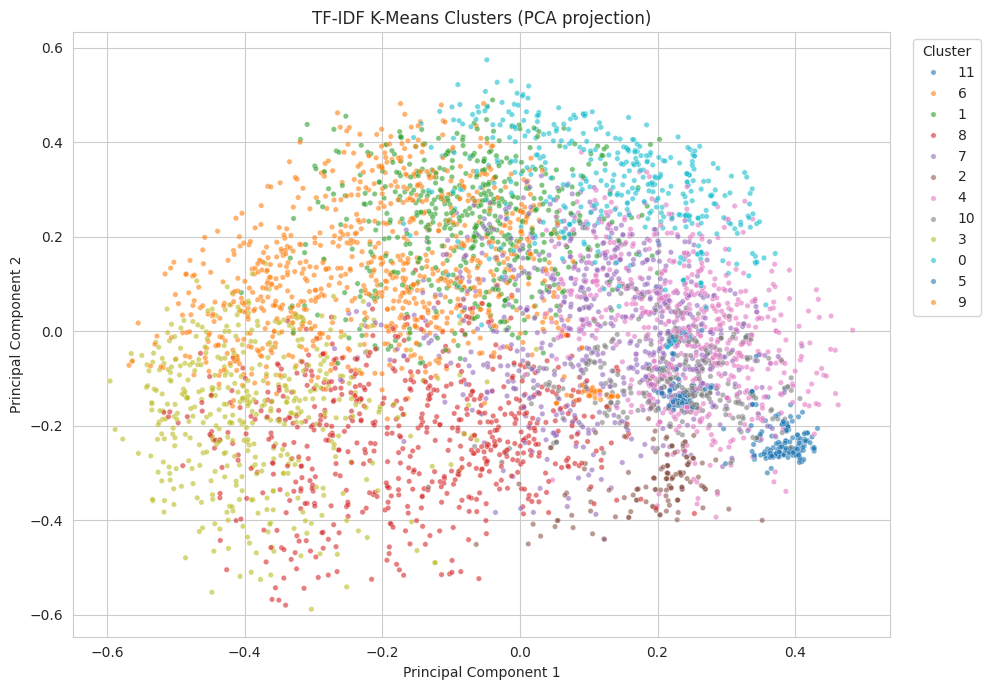

In [ ]:
def plot_clusters_2d(X, cluster_labels, title, filename):
    """Project the vectors to two dimensions with PCA and plot the clusters."""

    points = PCA(n_components=2, random_state=42).fit_transform(X)

    plot_df = pd.DataFrame({
        "PC1": points[:, 0],
        "PC2": points[:, 1],
        "Cluster": cluster_labels.astype(str)
    })

    plt.figure(figsize=(10, 7))

    sns.scatterplot(
        data=plot_df,
        x="PC1",
        y="PC2",
        hue="Cluster",
        palette="tab10",
        alpha=0.6,
        s=15
    )

    plt.title(title)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(output_dir / filename, dpi=150)
    plt.show()


plot_clusters_2d(
    X_tfidf_svd,
    df["tfidf_cluster"].values,
    "TF-IDF K-Means Clusters (PCA projection)",
    "tfidf_clusters_pca.png"
)

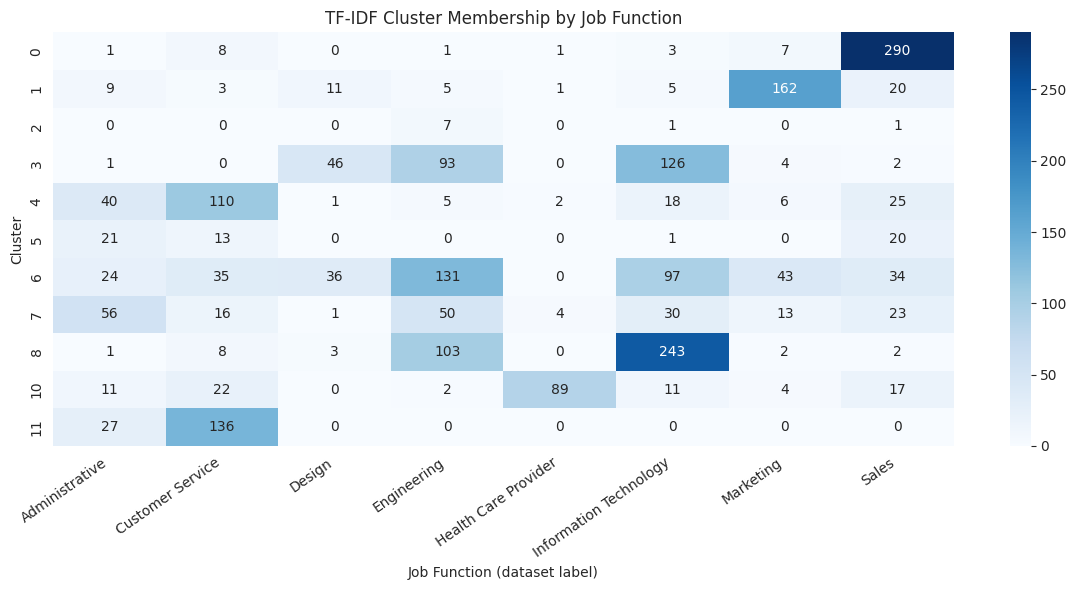

In [ ]:
def plot_cluster_vs_function(cluster_column, title, filename):
    """Show how the clusters relate to the job function column."""

    labelled = df.dropna(subset=["function"])
    top_function_names = labelled["function"].value_counts().head(8).index
    labelled = labelled[labelled["function"].isin(top_function_names)]

    ct = pd.crosstab(labelled[cluster_column], labelled["function"])

    plt.figure(figsize=(12, 6))

    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")

    plt.title(title)
    plt.xlabel("Job Function (dataset label)")
    plt.ylabel("Cluster")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(output_dir / filename, dpi=150)
    plt.show()


plot_cluster_vs_function(
    "tfidf_cluster",
    "TF-IDF Cluster Membership by Job Function",
    "tfidf_cluster_vs_function.png"
)

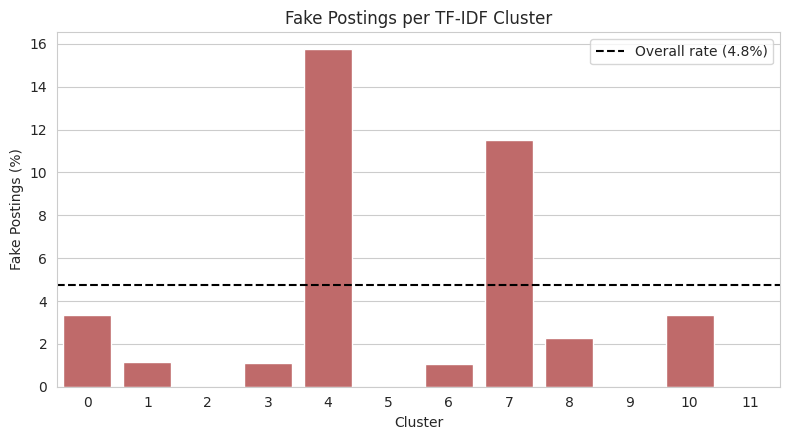

In [ ]:
def plot_fake_rate(cluster_column, title, filename):
    """Plot the percentage of fake postings in each cluster."""

    fake_rate = df.groupby(cluster_column)["fraudulent"].mean() * 100
    overall = df["fraudulent"].mean() * 100

    plt.figure(figsize=(8, 4.5))

    sns.barplot(
        x=fake_rate.index.astype(str),
        y=fake_rate.values,
        color="indianred"
    )

    plt.axhline(overall, color="black", linestyle="--",
                label=f"Overall rate ({overall:.1f}%)")

    plt.title(title)
    plt.xlabel("Cluster")
    plt.ylabel("Fake Postings (%)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / filename, dpi=150)
    plt.show()


plot_fake_rate(
    "tfidf_cluster",
    "Fake Postings per TF-IDF Cluster",
    "tfidf_fake_rate.png"
)

## 2.5 Transformer-Based Embeddings and Comparison

Sentence-BERT (`all-MiniLM-L6-v2`) produces a 384-dimensional embedding for each document. The Transformer receives
the lightly cleaned text rather than the lemmatised text, because it was trained on natural sentences and uses word
order and context. The model reads up to 256 word-pieces, so longer adverts are truncated.

In [ ]:
from sentence_transformers import SentenceTransformer

# Load the pre-trained Sentence-BERT model
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Maximum sequence length:", sbert_model.max_seq_length)

# Lightly clean the text for the Transformer
transformer_text = df["text"].apply(basic_clean).tolist()

# Generate the embeddings
start_time = time.time()

embeddings = sbert_model.encode(
    transformer_text,
    show_progress_bar=True,
    batch_size=64
)

sbert_time = time.time() - start_time

print("Embedding shape:", embeddings.shape)
print("Embedding time (seconds):", round(sbert_time, 2))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Maximum sequence length: 256


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Embedding shape: (5000, 384)
Embedding time (seconds): 746.02


In [ ]:
# Normalise the embeddings and reduce them to 50 dimensions
embeddings = normalize(embeddings)

pca = PCA(n_components=50, random_state=42)
X_sbert_pca = normalize(pca.fit_transform(embeddings))

print("Reduced embedding shape:", X_sbert_pca.shape)
print("Variance explained by 50 components (%):",
      round(pca.explained_variance_ratio_.sum() * 100, 2))

Reduced embedding shape: (5000, 50)
Variance explained by 50 components (%): 61.49


K selection time (seconds): 10.65


,K,Inertia,Silhouette
0,2,4651.4023,0.0687
1,3,4460.2852,0.0626
2,4,4341.3994,0.0581
3,5,4240.5752,0.0495
4,6,4154.9102,0.0521
5,7,4080.6753,0.0527
6,8,4007.5728,0.0577
7,9,3951.3730,0.0609
8,10,3891.7969,0.0635
9,11,3841.1919,0.0652


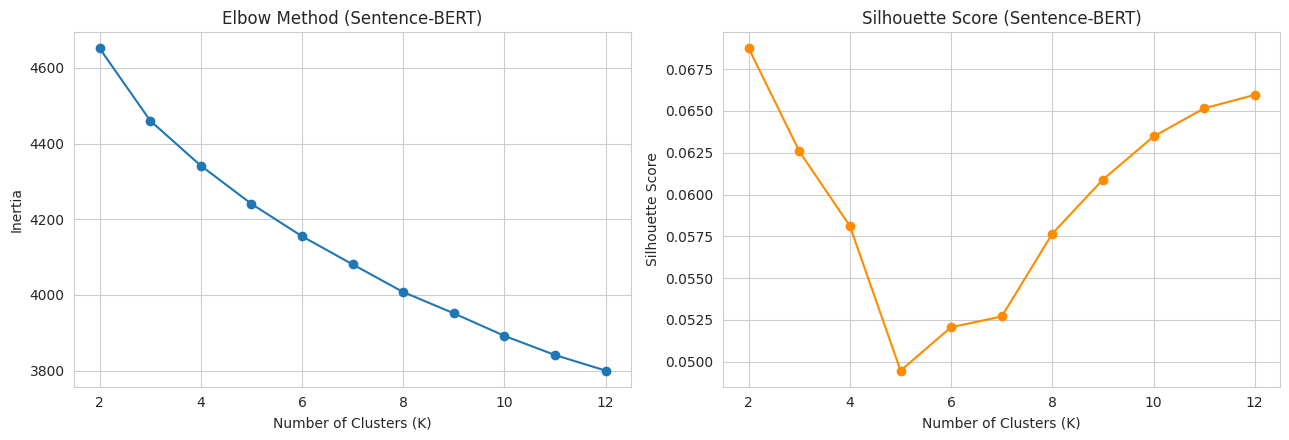

Selected K for Sentence-BERT: 12


In [ ]:
# Find a suitable K for the Transformer embeddings
start_time = time.time()
sbert_k_results = evaluate_k_values(X_sbert_pca, k_values)

print("K selection time (seconds):", round(time.time() - start_time, 2))
display(sbert_k_results.round(4))

plot_k_selection(sbert_k_results, "Sentence-BERT", "sbert_k_selection.png")

candidates = sbert_k_results[sbert_k_results["K"] >= 3]
best_k_sbert = int(candidates.loc[candidates["Silhouette"].idxmax(), "K"])

print("Selected K for Sentence-BERT:", best_k_sbert)

In [ ]:
# Cluster the embeddings with K-Means
kmeans_sbert = KMeans(
    n_clusters=best_k_sbert,
    random_state=42,
    n_init=20
)

df["sbert_cluster"] = kmeans_sbert.fit_predict(X_sbert_pca)

print("Documents per Sentence-BERT cluster:")
print(df["sbert_cluster"].value_counts().sort_index())

# Interpret the clusters using TF-IDF key terms
sbert_cluster_terms = top_terms_per_cluster(df["sbert_cluster"].values)

display(sbert_cluster_terms)
sbert_cluster_terms.to_csv(output_dir / "sbert_cluster_terms.csv", index=False)

Documents per Sentence-BERT cluster:
sbert_cluster
0     566
1     487
2     531
3     182
4     509
5     440
6     469
7     357
8     355
9     126
10    568
11    410
Name: count, dtype: int64


,Cluster,Documents,Fake (%),Top Terms
0,0,566,1.24,"team, business, sale, marketing, client, company, work, opportunity, account, new"
1,1,487,4.11,"sale, customer, service, product, work, food, team, must, company, home"
2,2,531,0.19,"design, team, product, web, work, designer, user, developer, mobile, development"
3,3,182,0.00,"customer, mail, document, document communication, increase productivity, service, productivity, required, business process, customer service"
4,4,509,1.18,"medium, marketing, social, digital, content, social medium, shall, brand, campaign, team"
5,5,440,15.00,"job, engineering, manufacturing, technical, project, equipment, work, process, website, company"
6,6,469,1.71,"data, technology, team, business, system, service, software, solution, development, customer"
7,7,357,4.20,"patient, care, health, medical, home, service, nurse, program, healthcare, clinical"
8,8,355,1.41,"english, company, international, service, team, babbel, customer, language, work, web"
9,9,126,0.79,"apprenticeship, recruitment, career, year old, course, old, education, role, apprenticeship available, long"


In [ ]:
# Show example job titles from each Sentence-BERT cluster
for cluster in sorted(df["sbert_cluster"].unique()):

    print("\n" + "=" * 70)
    print(f"SENTENCE-BERT CLUSTER {cluster}")
    print("=" * 70)

    sample_titles = df[df["sbert_cluster"] == cluster]["title"].head(8)

    for title in sample_titles:
        print("-", title)


SENTENCE-BERT CLUSTER 0
- Business, Customer Service, Social Media Internship
- Accounting Manager
- Data Engineer
- Community Ambassador German-speaking (Remote)
- Regional Manager
- VP Engineering
- Bank Mortgage Team Lead & Two Originators
- Senior Developer at a Startup Investment Studio 

SENTENCE-BERT CLUSTER 1
- Talent Manager
- Client Service Professional
- Buyers Admin Assistant
- Senior Salesperson/Store Manager
- Salon/Beauty Sales Professional
- Escrow Officer / Closer
- Performance Marketing Manager
- Title Insurance & Settlement Sales: Midwestern Account Executive

SENTENCE-BERT CLUSTER 2
- Full Stack API/Services Engineer
- Junior Software Engineer
- ASP.NET Web Developer
- Sales Representative EMEA
- Senior Computer Vision/Computational Imaging Engineer
- City Launcher 
- PHP Web Developer
- IT and Operations Manager - Figo Pet Insurance

SENTENCE-BERT CLUSTER 3
- Service Delivery Manager 1 
- Customer Service Associate 
- Senior Docket Clerk/Court Filer 
- Customer Se

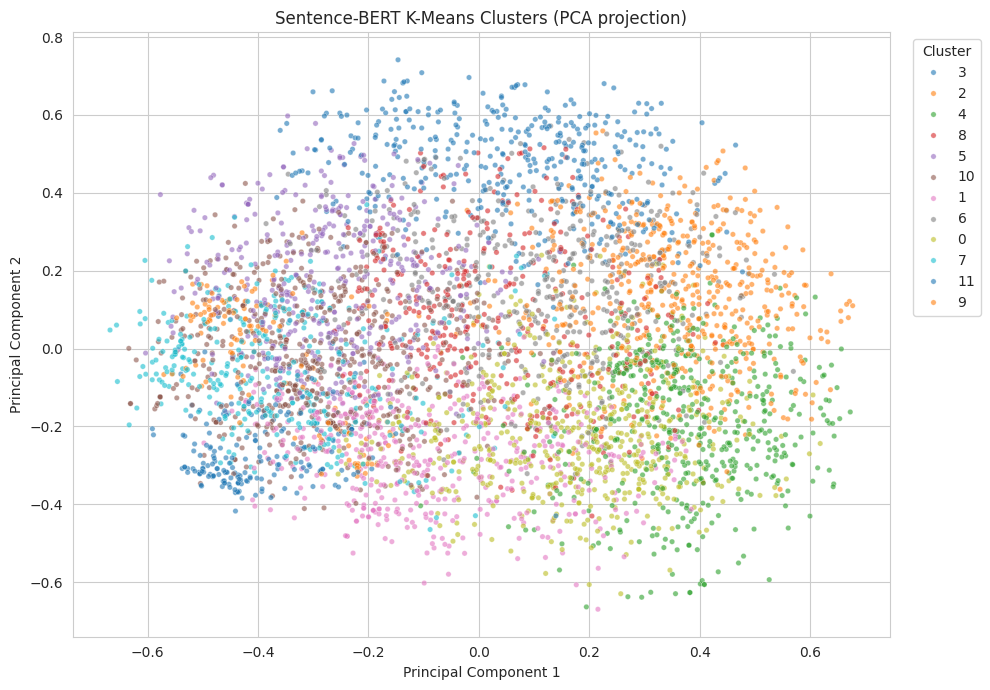

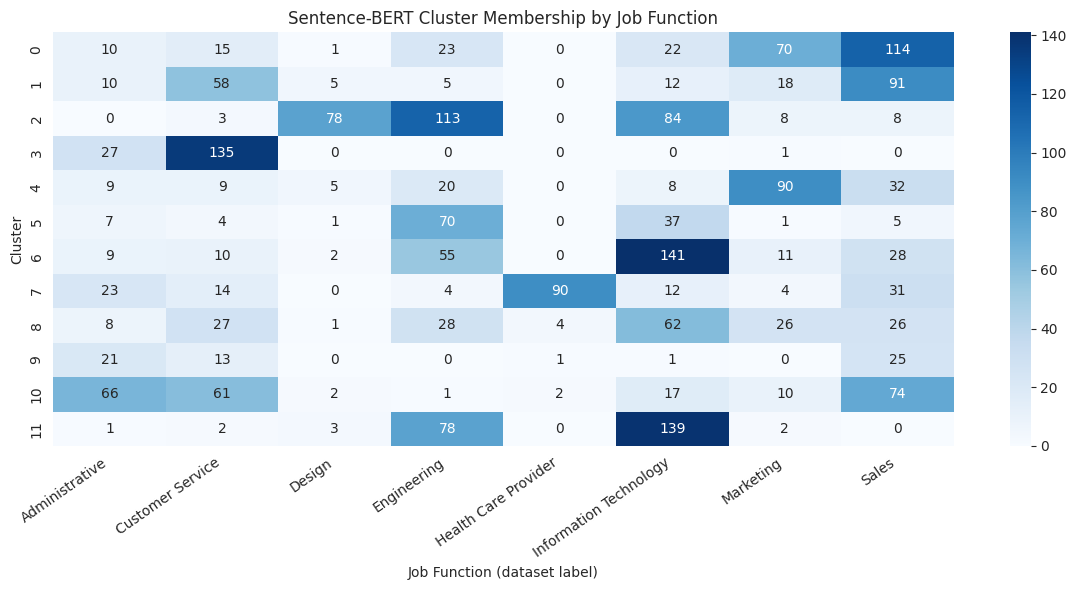

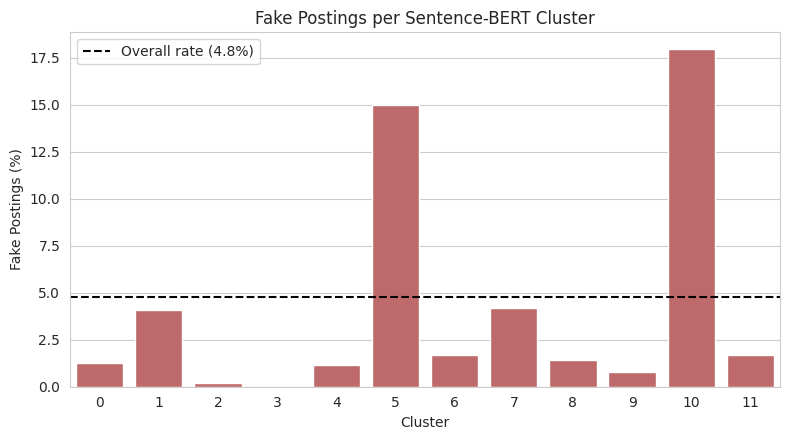

In [ ]:
plot_clusters_2d(
    X_sbert_pca,
    df["sbert_cluster"].values,
    "Sentence-BERT K-Means Clusters (PCA projection)",
    "sbert_clusters_pca.png"
)

plot_cluster_vs_function(
    "sbert_cluster",
    "Sentence-BERT Cluster Membership by Job Function",
    "sbert_cluster_vs_function.png"
)

plot_fake_rate(
    "sbert_cluster",
    "Fake Postings per Sentence-BERT Cluster",
    "sbert_fake_rate.png"
)

### Comparing cluster quality

Three **internal** measures (no labels needed) and two **external** measures are used:

* **Silhouette Score** (−1 to 1, higher is better): how close documents are to their own cluster compared with the nearest other cluster.
* **Calinski-Harabasz Index** (higher is better): ratio of between-cluster to within-cluster spread.
* **Davies-Bouldin Index** (lower is better): average similarity between each cluster and its most similar cluster.
* **NMI** and **ARI** against the dataset's `function` column (e.g. Sales, Engineering): how well the clusters match real job areas. This column was not used for clustering.

To make the comparison fair, both methods are also evaluated with the same number of clusters.

In [ ]:
def cluster_quality(X, cluster_labels, method, k):
    """Calculate internal and external cluster quality measures."""

    labelled = df["function"].notna().values

    return {
        "Method": method,
        "K": k,
        "Silhouette": silhouette_score(X, cluster_labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, cluster_labels),
        "Davies-Bouldin": davies_bouldin_score(X, cluster_labels),
        "NMI (function)": normalized_mutual_info_score(
            df.loc[labelled, "function"], cluster_labels[labelled]
        ),
        "ARI (function)": adjusted_rand_score(
            df.loc[labelled, "function"], cluster_labels[labelled]
        )
    }


# Use the same K for both methods for a direct comparison
common_k = best_k_tfidf

sbert_same_k = KMeans(
    n_clusters=common_k, random_state=42, n_init=20
).fit_predict(X_sbert_pca)

comparison = pd.DataFrame([
    cluster_quality(X_tfidf_svd, df["tfidf_cluster"].values,
                    "TF-IDF + K-Means", best_k_tfidf),
    cluster_quality(X_sbert_pca, sbert_same_k,
                    "Sentence-BERT + K-Means (same K)", common_k),
    cluster_quality(X_sbert_pca, df["sbert_cluster"].values,
                    "Sentence-BERT + K-Means (own best K)", best_k_sbert)
])

print("TF-IDF and Sentence-BERT Clustering Comparison")
display(comparison.round(4))

comparison.to_csv(output_dir / "clustering_comparison.csv", index=False)

# Measure how similar the two sets of clusters are
agreement = adjusted_rand_score(df["tfidf_cluster"], sbert_same_k)
print("\nAgreement between TF-IDF and Sentence-BERT clusters (ARI):",
      round(agreement, 4))

TF-IDF and Sentence-BERT Clustering Comparison


,Method,K,Silhouette,Calinski-Harabasz,Davies-Bouldin,NMI (function),ARI (function)
0,TF-IDF + K-Means,12,0.1316,208.8805,2.3366,0.3189,0.2003
1,Sentence-BERT + K-Means (same K),12,0.0655,143.3965,2.9593,0.2434,0.1109
2,Sentence-BERT + K-Means (own best K),12,0.0655,143.3965,2.9593,0.2434,0.1109



Agreement between TF-IDF and Sentence-BERT clusters (ARI): 0.1892


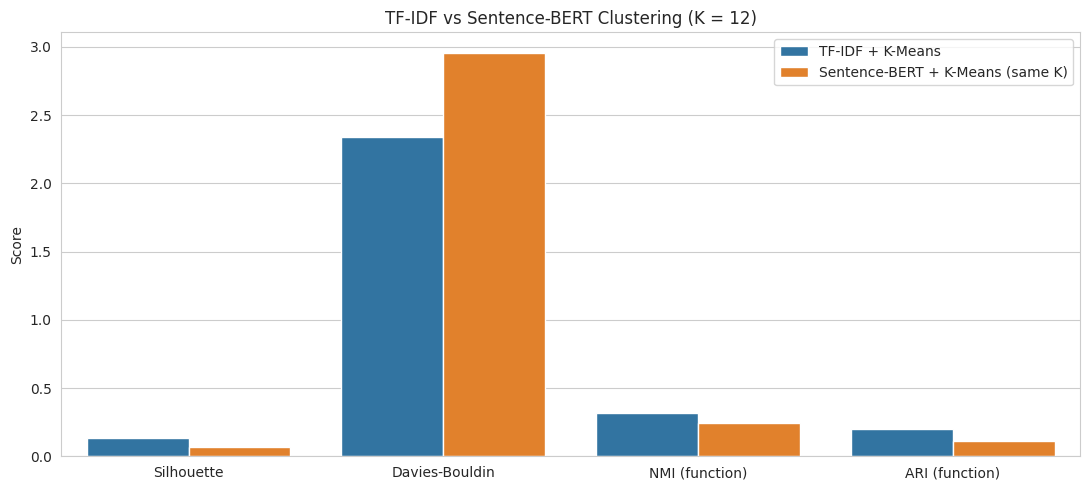

Note: for Davies-Bouldin a lower score is better; for the others higher is better.


In [ ]:
# Plot the comparison for the same number of clusters
plot_metrics = comparison.iloc[:2].melt(
    id_vars="Method",
    value_vars=["Silhouette", "Davies-Bouldin", "NMI (function)", "ARI (function)"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_metrics,
    x="Metric",
    y="Score",
    hue="Method"
)

plt.title(f"TF-IDF vs Sentence-BERT Clustering (K = {common_k})")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(output_dir / "tfidf_vs_sbert.png", dpi=150)
plt.show()

print("Note: for Davies-Bouldin a lower score is better; for the others higher is better.")

## 2.6 Results Summary

In [ ]:
# Summarise the main findings for the report
tfidf_row = comparison.iloc[0]
sbert_row = comparison.iloc[1]

print("Documents clustered:", len(df))
print("TF-IDF vocabulary size:", X_tfidf.shape[1])
print("Sentence-BERT embedding size:", embeddings.shape[1])
print("Sentence-BERT encoding time (s):", round(sbert_time, 2))

print("\nSelected K  -> TF-IDF:", best_k_tfidf, "| Sentence-BERT:", best_k_sbert)

for metric, higher_better in [
    ("Silhouette", True),
    ("Calinski-Harabasz", True),
    ("Davies-Bouldin", False),
    ("NMI (function)", True),
    ("ARI (function)", True)
]:
    t, s = tfidf_row[metric], sbert_row[metric]
    if np.isclose(t, s):
        better = "equal"
    else:
        better = "Sentence-BERT" if (s > t) == higher_better else "TF-IDF"
    print(f"{metric:<18} TF-IDF={t:.4f}  SBERT={s:.4f}  -> better: {better}")

# Highest fake rate found by each method
for column in ["tfidf_cluster", "sbert_cluster"]:
    rate = df.groupby(column)["fraudulent"].mean() * 100
    print(f"\n{column}: highest fake rate {rate.max():.1f}% in cluster {rate.idxmax()}")

# Save the clustered dataset
df[["title", "function", "fraudulent", "tfidf_cluster", "sbert_cluster"]].to_csv(
    output_dir / "clustered_job_postings.csv", index=False
)
print("\nResults saved to", output_dir)

Documents clustered: 5000
TF-IDF vocabulary size: 5000
Sentence-BERT embedding size: 384
Sentence-BERT encoding time (s): 746.02

Selected K  -> TF-IDF: 12 | Sentence-BERT: 12
Silhouette         TF-IDF=0.1316  SBERT=0.0655  -> better: TF-IDF
Calinski-Harabasz  TF-IDF=208.8805  SBERT=143.3965  -> better: TF-IDF
Davies-Bouldin     TF-IDF=2.3366  SBERT=2.9593  -> better: TF-IDF
NMI (function)     TF-IDF=0.3189  SBERT=0.2434  -> better: TF-IDF
ARI (function)     TF-IDF=0.2003  SBERT=0.1109  -> better: TF-IDF

tfidf_cluster: highest fake rate 15.7% in cluster 4

sbert_cluster: highest fake rate 18.0% in cluster 10

Results saved to /content/task2_results
